# Tune an IMSTE embedding on MNIST

This notebook tunes for a combined score: 80% 5-fold k-NN accuracy and 20% robust spatial coverage. Each trial embeds all selected feature rows; labels are used only for accuracy scoring. Change `SAMPLES_PER_CLASS` below to adjust the balanced sample (default: 100 per digit).

Install the optional optimizer with `python -m pip install 'imste[tuning]'` if needed.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
from IPython.display import display

repo_root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / 'notebooks' / 'src' / 'digits_sweep.py').is_file()
)
sys.path.insert(0, str(repo_root / 'notebooks' / 'src'))
sys.path.insert(0, str(repo_root))

from digits_sweep import (
    load_mnist_per_class_data,
    make_live_tuning_display,
    plot_mnist_embedding,
)
from imste import IteratedMinimumSpanningTreeEmbedder

## Select and prepare the data

Set `SAMPLES_PER_CLASS` and rerun this cell to use a different number of images per digit. Sampling is balanced and deterministic.

In [2]:
SAMPLES_PER_CLASS = 500  # Change this value to sample a different number per digit.
RANDOM_STATE = 42

X, y, data_info = load_mnist_per_class_data(
    samples_per_class=SAMPLES_PER_CLASS, random_state=RANDOM_STATE
)
print(
    f"Loaded {len(X):,} images from {data_info['source']} ({SAMPLES_PER_CLASS} per digit; {X.shape[1]} pixel features)."
)
display(data_info['class_counts'].to_frame())

Loaded 5,000 images from /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/mnist/cache/mnist_784_v1.npz (500 per digit; 784 pixel features).


,images
0,500
1,500
2,500
3,500
4,500
5,500
6,500
7,500
8,500
9,500


## Set up the search

The default search runs 40 total trials: 20 Latin hypercube starts followed by Bayesian optimization. IMSTE fits are the expensive part, so reduce `N_SAMPLES` or `N_EPOCHS` for a quick first run.

In [3]:
N_SAMPLES = 40
N_INITIAL_POINTS = 20
K = 5
COVERAGE_WEIGHT = 0.2
N_EPOCHS = 80

mapper = IteratedMinimumSpanningTreeEmbedder(
    n_epochs=N_EPOCHS, random_state=RANDOM_STATE, device='auto'
)
search_space = {
    'n_msts': (3, 30),
    'learning_rate': (0.01, 0.1),
    'negative_ratio': (1, 10),
    'gravity_strength': (0.0, 1.0),
    'mean_shift_iterations': (0, 5),
}

## Watch intermediate results

The table reports accuracy, spatial coverage, and the weighted objective after every trial. The plot updates when a trial improves the combined objective.

**Trial 40/40** — accuracy: 0.785; coverage: 0.029; objective: 0.634; best objective: 0.670

,accuracy,coverage,objective,best objective,n_msts,learning_rate,negative_ratio,gravity_strength,mean_shift_iterations
trial,,,,,,,,,
1,0.7110,0.111401,0.591080,0.591080,8,0.057692,2,6.014405e-01,4
2,0.7266,0.137636,0.608807,0.608807,9,0.074113,7,4.269158e-01,5
3,0.6842,0.222957,0.591951,0.608807,5,0.054781,9,1.053031e-01,4
4,0.6188,0.312403,0.557521,0.608807,23,0.012894,5,3.977781e-01,1
5,0.7282,0.100285,0.602617,0.608807,18,0.044585,3,6.877784e-01,2
6,0.7098,0.117104,0.591261,0.608807,19,0.091084,5,4.997167e-01,3
7,0.6912,0.196133,0.592187,0.608807,6,0.023630,6,5.191680e-01,2
8,0.7406,0.242539,0.640988,0.640988,14,0.062891,8,3.248097e-01,0
9,0.7264,0.048843,0.590889,0.640988,14,0.019763,4,9.564382e-01,3


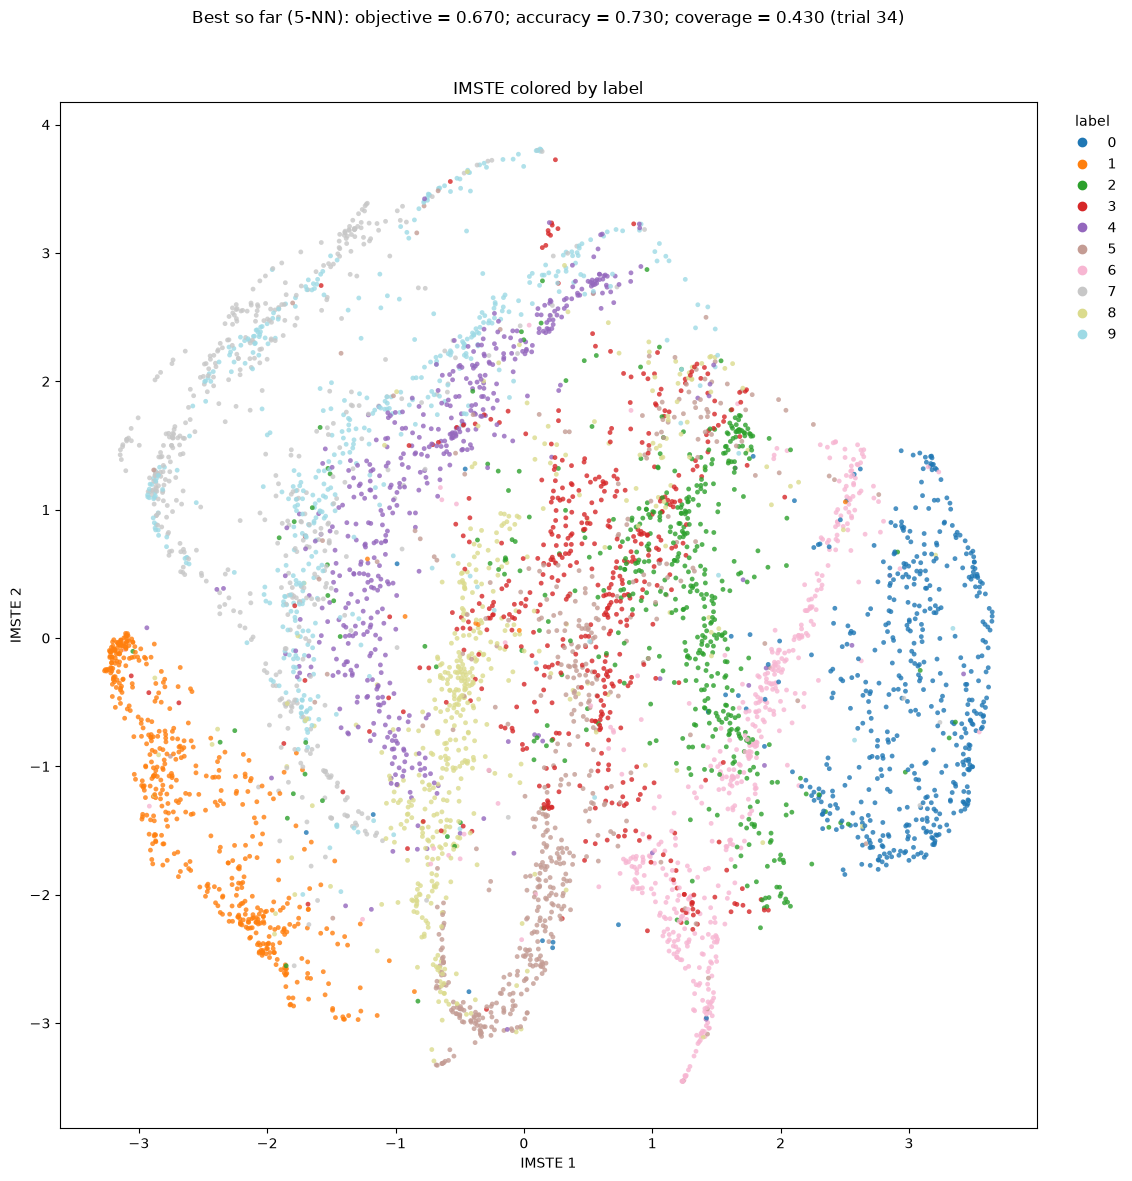

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(3), 0.1, np.int64(10), 1.0, np.int64(0)] before, using random point [np.int64(8), 0.09205213298247761, np.int64(2), 0.521858193371393, np.int64(4)]
  warnings.warn(
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(3), 0.1, np.int64(10), 1.0, np.int64(0)] before, using random point [np.int64(19), 0.08174515976120052, np.int64(8), 0.521097826378669, np.int64(5)]
  warnings.warn(
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(3), 0.1, np.int64(10), 1.0, np.int64(0)] before, using random point [np.int64(18), 0.08402069727623021, np.int64(8), 0.49422033922038966, np.int64(2)]
  warnings.warn(
/Users/f.costa/.venvs/py312/lib/p

Search and final refit completed in 0.9 minutes


In [4]:
show_trial, trial_rows = make_live_tuning_display(
    y, k=K, n_samples=N_SAMPLES
)

started = time.perf_counter()
search = mapper.tune(
    X, y,
    search_space=search_space,
    k=K,
    n_samples=N_SAMPLES,
    n_initial_points=N_INITIAL_POINTS,
    coverage_weight=COVERAGE_WEIGHT,
    trial_callback=show_trial,
)
elapsed = time.perf_counter() - started
print(f'Search and final refit completed in {elapsed / 60:.1f} minutes')

## Best result

The estimator is refitted on all selected images using the configuration with the highest weighted objective. The returned result retains the separate accuracy, coverage, and combined scores.

Best 5-fold 5-NN accuracy: 0.730
Best spatial coverage: 0.430
Best combined objective: 0.670


,best value
n_msts,3.0
learning_rate,0.1
negative_ratio,10.0
gravity_strength,0.0
mean_shift_iterations,0.0


(<Figure size 1560x1200 with 1 Axes>,
 array([[<Axes: title={'center': 'IMSTE colored by label'}, xlabel='IMSTE 1', ylabel='IMSTE 2'>]],
       dtype=object))

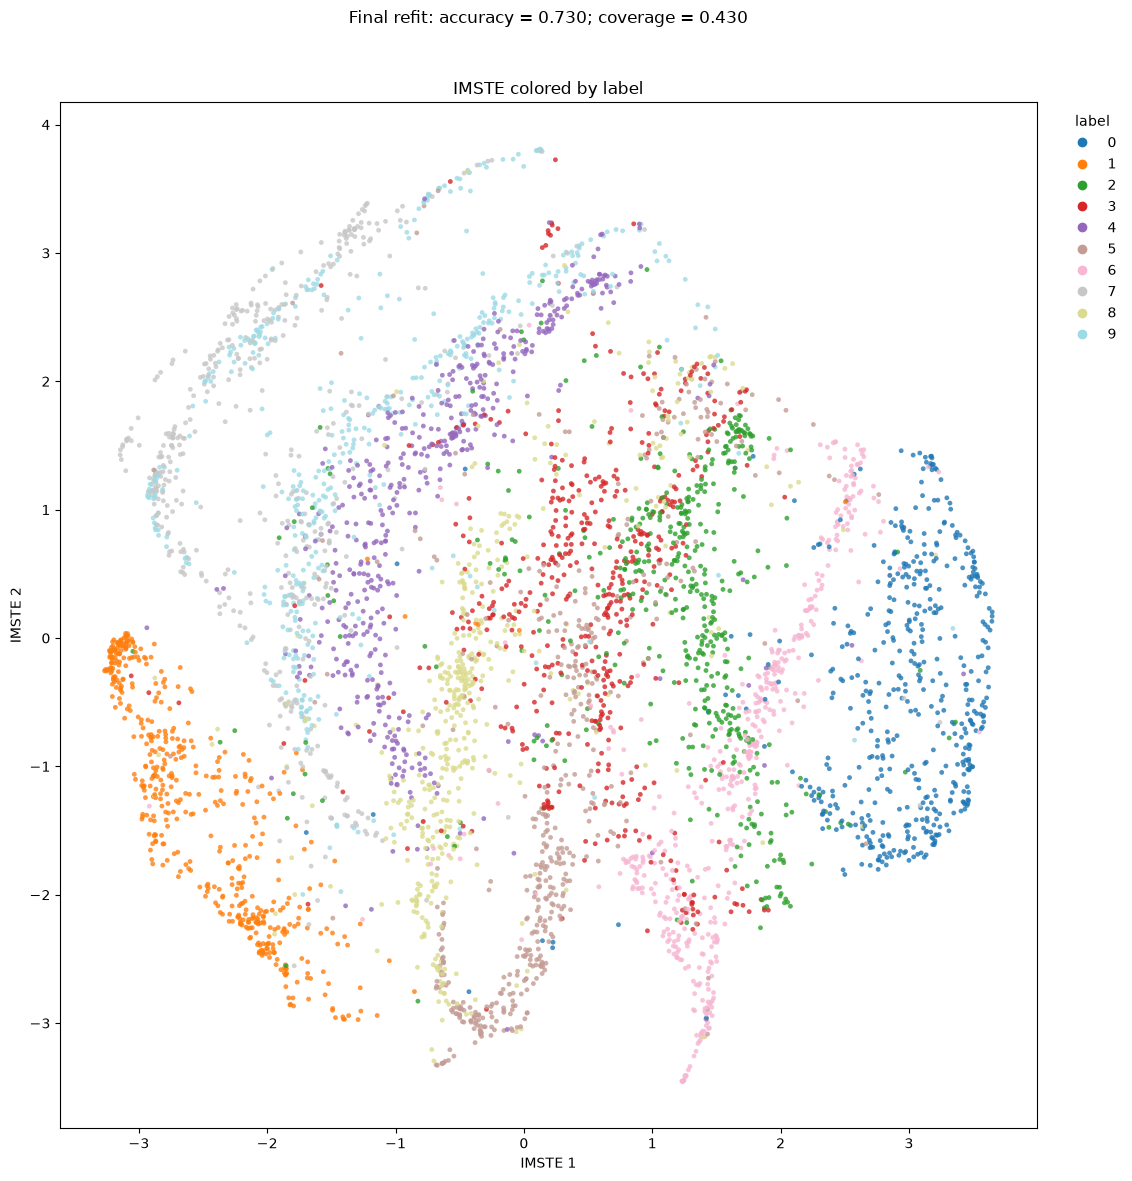

In [5]:
print(f"Best 5-fold {K}-NN accuracy: {search.best_accuracy:.3f}")
print(f"Best spatial coverage: {search.best_coverage:.3f}")
print(f"Best combined objective: {search.best_objective:.3f}")
display(pd.Series(search.best_params, name='best value').to_frame())
plot_mnist_embedding(
    mapper.embedding_, y,
    title=(
        f'Final refit: accuracy = {search.best_accuracy:.3f}; '
        f'coverage = {search.best_coverage:.3f}'
    ),
)